# 04 · Modelling, tuning, calibration and thresholds
**African Credit Scoring Challenge**

This notebook:
1. Screens and confirms settings for the competition model (R1) and the production model (P1).
2. Benchmarks logistic regression against LightGBM on the production features.
3. Checks calibration in time and forward in time, including recalibration on recent outcomes.
4. Chooses the competition threshold and writes the tuned submission.
5. Saves production scores for the scorecard (notebook 05).

**Protocol:** screening runs (`v2-screen-B`) only rank candidates; every reported number comes from a confirmed `v2-nested` run. Full run: about 35-45 minutes.

In [1]:
import sys, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

sys.path.insert(0, 'src')
from features import build_features
from evaluate import Evaluator, log_experiment
from modeling import (lgbm_factory, logistic_factory, calibration_table, calibration_summary,
                      fold_auc, top_share, platt_recalibrator)

warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)
DATA, OUT = Path('.'), Path('outputs')
train = pd.read_csv(DATA / 'Train.csv', parse_dates=['disbursement_date', 'due_date'])
test  = pd.read_csv(DATA / 'Test.csv',  parse_dates=['disbursement_date', 'due_date'])
econ  = pd.read_csv(DATA / 'economic_indicators.csv')
folds = pd.read_csv(OUT / 'folds.csv')
SETS  = json.loads((OUT / 'feature_sets.json').read_text())
R1, P1 = SETS['competition'], SETS['production']

feats = build_features(train, test, econ)
ev = Evaluator(train, test, feats, folds)
y = train['target'].to_numpy()
print(f'R1: {len(R1)} features | P1: {len(P1)} features')

R1: 10 features | P1: 9 features


## 1. Helper: screen a grid of settings
`screen()` runs scheme B only, logs every run as `v2-screen-B`, and returns a sorted table.

In [2]:
def screen(prefix, cols, grid, metric):
    rows = []
    for label, params in grid.items():
        ev.model_factory = lgbm_factory(**params)
        start = time.time()
        r = ev.run(f'M4 {prefix} {label}', cols, schemes=('B',), protocol='v2-screen-B', verbose=False)
        log_experiment(r)
        rows.append({'setting': label, 'f1_B': r['f1_B'], 'f1_B_sd': r['f1_B_sd'], 'roc_auc_B': r['roc_auc_B'],
                     'pr_auc_B': r['pr_auc_B'], 'flag_rate_Ghana': r['flag_rate_Ghana'],
                     'seconds': round(time.time() - start), 'params': params})
    return pd.DataFrame(rows).sort_values(metric, ascending=False).set_index('setting')

## 2. Competition model (R1): screen
Judged on F1, the competition metric.

In [3]:
R1_GRID = {
    'default': {},
    'leaves15': dict(num_leaves=15), 'leaves63': dict(num_leaves=63),
    'mcs100': dict(min_child_samples=100), 'mcs5': dict(min_child_samples=5),
    'slow600': dict(n_estimators=600, learning_rate=0.025), 'fast150': dict(n_estimators=150, learning_rate=0.1),
    'lambda5': dict(reg_lambda=5.0),
    'col08_sub08': dict(colsample_bytree=0.8, subsample=0.8, subsample_freq=1),
    'leaves15_mcs50_l1': dict(num_leaves=15, min_child_samples=50, reg_lambda=1.0),
    'leaves63_mcs50_slow': dict(num_leaves=63, min_child_samples=50, n_estimators=600, learning_rate=0.025),
    'n1000_lr001': dict(n_estimators=1000, learning_rate=0.01),
}
r1_screen = screen('R1 screen', R1, R1_GRID, metric='f1_B')
display(r1_screen.drop(columns='params').round(4))
d = r1_screen.loc['default']
print(f"Range of F1 B across {len(r1_screen)} settings: {r1_screen.f1_B.min():.3f}-{r1_screen.f1_B.max():.3f}; "
      f"default {d.f1_B:.3f} ± {d.f1_B_sd:.3f}.")

,f1_B,f1_B_sd,roc_auc_B,pr_auc_B,flag_rate_Ghana,seconds
setting,,,,,,
n1000_lr001,0.8354,0.0087,0.9937,0.9138,0.1126,61
col08_sub08,0.8340,0.0043,0.9940,0.9141,0.1132,22
default,0.8333,0.0096,0.9933,0.9114,0.1047,21
mcs100,0.8325,0.0068,0.9933,0.9122,0.0945,24
leaves15_mcs50_l1,0.8324,0.0165,0.9938,0.9149,0.1050,17
leaves15,0.8320,0.0162,0.9937,0.9132,0.1081,16
lambda5,0.8313,0.0168,0.9939,0.9162,0.1030,21
mcs5,0.8308,0.0078,0.9931,0.8885,0.1041,20
slow600,0.8303,0.0071,0.9936,0.9111,0.1177,39


Range of F1 B across 12 settings: 0.822-0.835; default 0.833 ± 0.010.


In [4]:
# Two extra settings, screened against the default.
#
# Two settings that demand more evidence per rule, in different ways:
#   depth4 - every tree at most 4 levels deep (so at most 16 leaves): no rule combines more than 4 conditions
#   mcs50  - keeps 31 leaves but needs at least 50 loans behind each leaf (default is 20)
# Only the two new settings are trained here; the other 12 are already in r1_screen.
MY_R1_GRID = {
    'depth4': dict(max_depth=4),
    'mcs50':  dict(min_child_samples=50),
}
my_screen = screen('R1 screen', R1, MY_R1_GRID, metric='f1_B')
R1_GRID.update(MY_R1_GRID)
r1_screen = pd.concat([r1_screen, my_screen]).sort_values('f1_B', ascending=False)
display(r1_screen.drop(columns='params').round(4))

# Protocol rule 4: a real gain beats the default by more than one fold sd OR is better in at least 4 of 5 folds.
screen_log = pd.read_csv(OUT / 'experiments.csv').set_index('experiment')

def screen_folds(label):
    return np.array(screen_log.loc[f'M4 R1 screen {label}', 'f1_B_folds'].split(), float)

d = r1_screen.loc['default']
for label in MY_R1_GRID:
    s = r1_screen.loc[label]
    gain = s.f1_B - d.f1_B
    fold_wins = int((screen_folds(label) > screen_folds('default')).sum())
    beats = (gain > d.f1_B_sd) or (fold_wins >= 4)
    print(f"{label}: F1 B {s.f1_B:.3f} ± {s.f1_B_sd:.3f} vs default {d.f1_B:.3f} ± {d.f1_B_sd:.3f} "
          f"({gain:+.3f}, {'more' if gain > d.f1_B_sd else 'less'} than one fold sd), better in {fold_wins}/5 folds, "
          f"so it {'beats' if beats else 'does not beat'} the default beyond the noise.")

,f1_B,f1_B_sd,roc_auc_B,pr_auc_B,flag_rate_Ghana,seconds
setting,,,,,,
n1000_lr001,0.8354,0.0087,0.9937,0.9138,0.1126,61
depth4,0.8352,0.0145,0.9939,0.9145,0.1172,15
mcs50,0.8347,0.0130,0.9934,0.9110,0.1087,21
col08_sub08,0.8340,0.0043,0.9940,0.9141,0.1132,22
default,0.8333,0.0096,0.9933,0.9114,0.1047,21
mcs100,0.8325,0.0068,0.9933,0.9122,0.0945,24
leaves15_mcs50_l1,0.8324,0.0165,0.9938,0.9149,0.1050,17
leaves15,0.8320,0.0162,0.9937,0.9132,0.1081,16
lambda5,0.8313,0.0168,0.9939,0.9162,0.1030,21


depth4: F1 B 0.835 ± 0.014 vs default 0.833 ± 0.010 (+0.002, less than one fold sd), better in 3/5 folds, so it does not beat the default beyond the noise.
mcs50: F1 B 0.835 ± 0.013 vs default 0.833 ± 0.010 (+0.001, less than one fold sd), better in 3/5 folds, so it does not beat the default beyond the noise.


## 3. Competition model (R1): confirm the shortlist with the full protocol

In [5]:
def confirm(prefix, cols, candidates):
    out = {}
    for label, factory in candidates.items():
        ev.model_factory = factory
        r = ev.run(f'M4 {prefix} {label}', cols)          # full nested protocol, logged as v2-nested
        r['fold_auc_B'] = ' '.join(f'{v:.4f}' for v in fold_auc(y, ev.last_oof_B, ev.fold_loan))
        log_experiment(r)
        out[label] = {'r': r, 'oof': ev.last_oof_B.copy(), 'test': ev.last_test_prob.copy()}
    return out

def wins(child, parent, key):
    a = np.array(parent['r'][key].split(), float); b = np.array(child['r'][key].split(), float)
    return int((b > a).sum())

r1_conf = confirm('R1 confirm', R1, {
    'default':     lgbm_factory(),
    'n1000_lr001': lgbm_factory(n_estimators=1000, learning_rate=0.01),
    'col08_sub08': lgbm_factory(colsample_bytree=0.8, subsample=0.8, subsample_freq=1),
    'mcs100':      lgbm_factory(min_child_samples=100),
})

M4 R1 confirm default: F1 B 0.833 ± 0.010 | C 0.821 | D 0.578 | E AUC 0.949 | Ghana flag 10.5%


M4 R1 confirm n1000_lr001: F1 B 0.835 ± 0.009 | C 0.827 | D 0.422 | E AUC 0.937 | Ghana flag 11.3%


M4 R1 confirm col08_sub08: F1 B 0.834 ± 0.004 | C 0.830 | D 0.566 | E AUC 0.927 | Ghana flag 11.3%


M4 R1 confirm mcs100: F1 B 0.832 ± 0.007 | C 0.819 | D 0.468 | E AUC 0.945 | Ghana flag 9.4%


In [6]:
TOL = 0.010
base = r1_conf['default']['r']
rows = []
for label, res in r1_conf.items():
    r = res['r']
    row = {'setting': label, 'f1_B': r['f1_B'], 'f1_B_sd': r['f1_B_sd'], 'f1_C': r['f1_C'], 'f1_D': r['f1_D'],
           'auc_E_mean': r['auc_E_mean'], 'flag_rate_Ghana': r['flag_rate_Ghana']}
    if label != 'default':
        gain = r['f1_B'] - base['f1_B']; w = wins(res, r1_conf['default'], 'f1_B_folds')
        guard = {s: r[k] - base[k] for s, k in [('C', 'f1_C'), ('D', 'f1_D'), ('E', 'auc_E_mean')]}
        row.update(fold_wins=w, passes=((gain > base['f1_B_sd']) or w >= 4) and all(v >= -TOL for v in guard.values()),
                   worst_guardrail=min(guard, key=guard.get), worst_drop=min(guard.values()))
    rows.append(row)
r1_table = pd.DataFrame(rows).set_index('setting')
display(r1_table.round(3))
winners = r1_table.index[r1_table.get('passes', pd.Series(dtype=bool)).fillna(False).astype(bool)].tolist()
R1_CHOICE = winners[0] if winners else 'default'
print(f"Settings that pass the protocol against the default: {winners or 'none'}. R1 uses: {R1_CHOICE}.")

,f1_B,f1_B_sd,f1_C,f1_D,auc_E_mean,flag_rate_Ghana,fold_wins,passes,worst_guardrail,worst_drop
setting,,,,,,,,,,
default,0.833,0.010,0.821,0.578,0.949,0.105,NaN,NaN,NaN,NaN
n1000_lr001,0.835,0.009,0.827,0.422,0.937,0.113,3.0,False,D,-0.157
col08_sub08,0.834,0.004,0.830,0.566,0.927,0.113,3.0,False,E,-0.022
mcs100,0.832,0.007,0.819,0.468,0.945,0.094,3.0,False,D,-0.110


Settings that pass the protocol against the default: none. R1 uses: default.


In [7]:
# Why the setting with the highest scheme B F1 was rejected.
GUARD_METRIC = {'C': 'f1_C', 'D': 'f1_D', 'E': 'auc_E_mean'}
challengers = r1_table.drop(index='default')
top = challengers['f1_B'].idxmax()
row, base_row = r1_table.loc[top], r1_table.loc['default']
gain = row.f1_B - base_row.f1_B
g = row['worst_guardrail']
metric = GUARD_METRIC[g]

print(f"The highest scheme B setting, {top}, scored F1 {row.f1_B:.3f} against the default's {base_row.f1_B:.3f} "
      f"({gain:+.3f}, {'less' if gain <= base_row.f1_B_sd else 'more'} than one fold sd of {base_row.f1_B_sd:.3f}), "
      f"and was better in only {int(row.fold_wins)}/5 folds.")
if bool(row['passes']):
    print(f"{top} passed every guardrail, so it was not rejected: check R1_CHOICE ({R1_CHOICE}).")
else:
    print(f"It was rejected on scheme {g}: {metric} fell from {base_row[metric]:.3f} to {row[metric]:.3f} "
          f"({row.worst_drop:+.3f}), beyond the {TOL:.3f} tolerance.")
print(f"Across all {len(r1_screen)} screened settings scheme B F1 ranged only {r1_screen.f1_B.min():.3f}-"
      f"{r1_screen.f1_B.max():.3f}, so choosing the maximum on one scheme mostly picks luck; the guardrails show that "
      f"the setting that fits the validation folds best was the one that transferred worst on scheme {g}.")

The highest scheme B setting, n1000_lr001, scored F1 0.835 against the default's 0.833 (+0.002, less than one fold sd of 0.010), and was better in only 3/5 folds.
It was rejected on scheme D: f1_D fell from 0.578 to 0.422 (-0.157), beyond the 0.010 tolerance.
Across all 14 screened settings scheme B F1 ranged only 0.822-0.835, so choosing the maximum on one scheme mostly picks luck; the guardrails show that the setting that fits the validation folds best was the one that transferred worst on scheme D.


## 4. Production model (P1): screen for ranking
Judged on ROC AUC, because the production track ends in risk bands, not a single cut-off.

In [8]:
P1_GRID = {
    'default': {},
    'leaves7': dict(num_leaves=7), 'leaves15': dict(num_leaves=15),
    'mcs100': dict(min_child_samples=100), 'mcs300': dict(min_child_samples=300),
    'leaves15_mcs100': dict(num_leaves=15, min_child_samples=100),
    'leaves7_mcs200_slow': dict(num_leaves=7, min_child_samples=200, n_estimators=600, learning_rate=0.025),
    'slow600': dict(n_estimators=600, learning_rate=0.025), 'fast150': dict(n_estimators=150, learning_rate=0.1),
    'lambda5': dict(reg_lambda=5.0),
    'col08_sub08': dict(colsample_bytree=0.8, subsample=0.8, subsample_freq=1),
    'leaves15_mcs100_col08': dict(num_leaves=15, min_child_samples=100, colsample_bytree=0.8,
                                  subsample=0.8, subsample_freq=1),
}
p1_screen = screen('P1 screen', P1, P1_GRID, metric='roc_auc_B')
display(p1_screen.drop(columns='params').round(4))

,f1_B,f1_B_sd,roc_auc_B,pr_auc_B,flag_rate_Ghana,seconds
setting,,,,,,
leaves7,0.2647,0.0338,0.8717,0.2221,0.1841,13
leaves7_mcs200_slow,0.2648,0.0258,0.8716,0.2263,0.1450,23
leaves15,0.2599,0.0410,0.8676,0.2133,0.1906,15
leaves15_mcs100_col08,0.2511,0.0266,0.8671,0.2209,0.1418,19
leaves15_mcs100,0.2540,0.0219,0.8645,0.2141,0.1433,16
lambda5,0.2582,0.0354,0.8624,0.2167,0.1390,22
col08_sub08,0.2412,0.0265,0.8597,0.2070,0.1359,22
slow600,0.2406,0.0260,0.8595,0.2066,0.1452,36
default,0.2384,0.0356,0.8572,0.1980,0.1509,18


## 5. Production model (P1): confirm, with logistic regression as a benchmark

In [9]:
P1_TUNED = dict(num_leaves=7, min_child_samples=200, n_estimators=600, learning_rate=0.025)
p1_conf = confirm('P1 confirm', P1, {
    'default':  lgbm_factory(),
    'tuned':    lgbm_factory(**P1_TUNED),
    'leaves7':  lgbm_factory(num_leaves=7),
    'logistic': logistic_factory(['lender_id', 'loan_type'], C=1.0),
})
base = p1_conf['default']
rows = []
for label, res in p1_conf.items():
    r = res['r']
    rows.append({'model': label, 'roc_auc_B': r['roc_auc_B'], 'auc_fold_wins_vs_default': wins(res, base, 'fold_auc_B'),
                 'pr_auc_B': r['pr_auc_B'], 'f1_B': r['f1_B'], 'auc_E_mean': r['auc_E_mean'],
                 'f1_D': r['f1_D'], 'flag_rate_Kenya': r['flag_rate_Kenya'], 'flag_rate_Ghana': r['flag_rate_Ghana']})
p1_table = pd.DataFrame(rows).set_index('model')
display(p1_table.round(3))
t = p1_table.loc['tuned']
print(f"P1 tuned: ROC AUC {t.roc_auc_B:.3f} vs default {p1_table.loc['default', 'roc_auc_B']:.3f}, "
      f"higher in {int(t.auc_fold_wins_vs_default)}/5 folds; held-out-lender AUC {t.auc_E_mean:.3f} vs "
      f"{p1_table.loc['default', 'auc_E_mean']:.3f}. Logistic regression flags {p1_table.loc['logistic', 'flag_rate_Ghana']:.1%} of Ghana loans.")

M4 P1 confirm default: F1 B 0.238 ± 0.036 | C 0.235 | D 0.145 | E AUC 0.663 | Ghana flag 15.1%


M4 P1 confirm tuned: F1 B 0.265 ± 0.026 | C 0.252 | D 0.153 | E AUC 0.714 | Ghana flag 14.5%


M4 P1 confirm leaves7: F1 B 0.265 ± 0.034 | C 0.255 | D 0.148 | E AUC 0.648 | Ghana flag 18.4%


M4 P1 confirm logistic: F1 B 0.248 ± 0.037 | C 0.240 | D 0.207 | E AUC 0.708 | Ghana flag 56.9%


,roc_auc_B,auc_fold_wins_vs_default,pr_auc_B,f1_B,auc_E_mean,f1_D,flag_rate_Kenya,flag_rate_Ghana
model,,,,,,,,
default,0.857,0,0.198,0.238,0.663,0.145,0.028,0.151
tuned,0.872,5,0.226,0.265,0.714,0.153,0.016,0.145
leaves7,0.872,5,0.222,0.265,0.648,0.148,0.019,0.184
logistic,0.839,0,0.197,0.248,0.708,0.207,0.030,0.569


P1 tuned: ROC AUC 0.872 vs default 0.857, higher in 5/5 folds; held-out-lender AUC 0.714 vs 0.663. Logistic regression flags 56.9% of Ghana loans.


In [10]:
# Why logistic regression flags far more Ghana loans than the tree models.
CATS = ['lender_id', 'loan_type']
num_cols = [c for c in P1 if c not in CATS]
gh = test['country_id'].eq('Ghana').to_numpy()
ke = ~gh

# 1. How far Ghana sits outside the Kenyan training range, per numeric feature
lo, hi = ev.X[num_cols].quantile(0.01), ev.X[num_cols].quantile(0.99)
Xg = ev.X_test.loc[gh, num_cols]
outside = ((Xg < lo) | (Xg > hi)).mean()

# 2. Refit the logistic model on all training rows (the same final model behind its test scores) and split each
#    test loan's log-odds into one contribution per original feature (coefficient x transformed value).
lr_full = logistic_factory(CATS)().fit(ev.X[P1], y)
pre, lr_model = lr_full.named_steps['pre'], lr_full.named_steps['model']
coef, names = lr_model.coef_[0], pre.get_feature_names_out()
dense = lambda M: M.toarray() if hasattr(M, 'toarray') else np.asarray(M)
Z, Z_train = dense(pre.transform(ev.X_test[P1])), dense(pre.transform(ev.X[P1]))

def source(name):
    # 'num__duration' -> 'duration'; 'num__missingindicator_x' -> 'x'; 'cat__loan_type_Type_1' -> 'loan_type'
    name = name.split('__', 1)[1]
    for c in CATS:
        if name.startswith(c + '_'):
            return c
    return name.replace('missingindicator_', '')

contrib = pd.DataFrame(Z * coef, columns=[source(n) for n in names]).T.groupby(level=0).sum().T
gap = (contrib[gh].mean() - contrib[ke].mean()).sort_values(ascending=False)
zcol = {n.split('__', 1)[1]: i for i, n in enumerate(names) if n.startswith('num__') and 'missingindicator' not in n}
lr_ghana = pd.DataFrame({
    'coef_per_sd': pd.Series({c: coef[zcol[c]] for c in num_cols}),
    'kenya_test_mean_z': pd.Series({c: Z[ke, zcol[c]].mean() for c in num_cols}),
    'ghana_mean_z': pd.Series({c: Z[gh, zcol[c]].mean() for c in num_cols}),
    'ghana_outside_p1_p99': outside,
    'logodds_gap_ghana_vs_kenya': gap,
}).sort_values('logodds_gap_ghana_vs_kenya', ascending=False)
display(lr_ghana.round(3))

# 3. Unseen codes: OneHotEncoder(handle_unknown='ignore') gives them all zeros, i.e. no category weight at all.
unseen_code = (~test['loan_type'].isin(train['loan_type'].unique()) | ~test['lender_id'].isin(train['lender_id'].unique())).to_numpy()
cat_idx = [i for i, n in enumerate(names) if n.startswith('cat__')]
cat_effect_test = Z[:, cat_idx] @ coef[cat_idx]
cat_effect_kenya = float((Z_train[:, cat_idx] @ coef[cat_idx]).mean())
thr_lr = p1_conf['logistic']['r']['threshold_B']
logit = Z @ coef + lr_model.intercept_[0]
p_lr = 1 / (1 + np.exp(-logit))
p_cf = 1 / (1 + np.exp(-(logit - cat_effect_test + cat_effect_kenya)))   # give Ghana the average Kenyan category effect
type1_w = coef[list(names).index('cat__loan_type_Type_1')]
lr_flag, tree_flag = (p_lr[gh] >= thr_lr).mean(), p1_table.loc['tuned', 'flag_rate_Ghana']
cf_flag = (p_cf[gh] >= thr_lr).mean()
num_gap = gap[[c for c in gap.index if c in num_cols]]
display(pd.DataFrame({'loans': pd.Series(test.loc[gh, 'loan_type']).value_counts(),
                      'logistic_flag_rate': pd.Series(p_lr[gh] >= thr_lr, index=test.index[gh]).groupby(test.loc[gh, 'loan_type']).mean(),
                      'tree_mean_pd': pd.Series(p1_conf['tuned']['test'][gh], index=test.index[gh]).groupby(test.loc[gh, 'loan_type']).mean()}).round(3))

print(f"Logistic regression flags {lr_flag:.1%} of Ghana loans (mean PD {p_lr[gh].mean():.1%}) against {tree_flag:.1%} "
      f"(mean PD {p1_conf['tuned']['test'][gh].mean():.1%}) for P1 tuned, both at cut-offs chosen on Kenya.")
print(f"Almost all of it comes from the codes: {unseen_code[gh].mean():.0%} of Ghana rows have a lender or product never "
      f"seen in training, the one-hot encoder turns those into all zeros, and so they lose the negative category weights "
      f"every Kenyan loan carries (on average {cat_effect_kenya:+.2f} log-odds; Type_1 alone {type1_w:+.2f}); that adds "
      f"{cat_effect_test[gh].mean() - cat_effect_kenya:+.2f} to the log-odds, about "
      f"{np.exp(cat_effect_test[gh].mean() - cat_effect_kenya):.0f}x the odds, and giving Ghana the average Kenyan "
      f"category effect instead cuts the flag rate from {lr_flag:.1%} to {cf_flag:.1%}, while the largest numeric push "
      f"({num_gap.index[0]}, {outside[num_gap.index[0]]:.0%} of Ghana rows outside Kenya's 1st-99th percentile) adds only "
      f"{num_gap.iloc[0]:+.2f}.")
print("A linear model has no neutral value for something it has never seen, so whatever the encoding's zero means "
      "becomes the default, and numeric values beyond the training range push the log-odds along the same straight line "
      "without limit, whereas a tree routes unseen codes down an existing branch and plateaus at its last split; a "
      "logistic scorecard for a new market therefore needs an explicit 'unknown' level (for example weight of evidence "
      "set to the portfolio average), capped or binned numeric inputs, and a local validation sample before it is used.")

,coef_per_sd,kenya_test_mean_z,ghana_mean_z,ghana_outside_p1_p99,logodds_gap_ghana_vs_kenya
loan_type,NaN,NaN,NaN,NaN,1.908
lender_id,NaN,NaN,NaN,NaN,0.464
hist_n_prior,-1.104,0.003,-0.415,0.000,0.461
duration,0.066,-0.019,2.053,0.138,0.138
hist_days_since_last,0.044,-0.010,0.592,0.054,0.046
hist_log_amount_vs_prior,0.294,-0.007,0.050,0.000,0.036
is_new,0.052,-0.015,0.112,0.018,0.007
log_amount_lcu,0.009,-0.018,-0.200,0.032,-0.002
lender_share,0.072,0.002,-0.478,0.015,-0.035


,loans,logistic_flag_rate,tree_mean_pd
loan_type,,,
Type_2,449,1.0,0.641
Type_3,3039,0.5,0.046
Type_8,37,1.0,0.282


Logistic regression flags 56.9% of Ghana loans (mean PD 16.9%) against 14.5% (mean PD 12.4%) for P1 tuned, both at cut-offs chosen on Kenya.
Almost all of it comes from the codes: 97% of Ghana rows have a lender or product never seen in training, the one-hot encoder turns those into all zeros, and so they lose the negative category weights every Kenyan loan carries (on average -2.27 log-odds; Type_1 alone -1.97); that adds +2.36 to the log-odds, about 11x the odds, and giving Ghana the average Kenyan category effect instead cuts the flag rate from 56.9% to 2.3%, while the largest numeric push (hist_n_prior, 0% of Ghana rows outside Kenya's 1st-99th percentile) adds only +0.46.
A linear model has no neutral value for something it has never seen, so whatever the encoding's zero means becomes the default, and numeric values beyond the training range push the log-odds along the same straight line without limit, whereas a tree routes unseen codes down an existing branch and plateaus at its 

## 6. Calibration in time
Ten equal-sized groups by predicted PD: does each group default at about the rate it was given?

,mean_predicted,actual_rate,brier,log_loss,expected_calibration_error,roc_auc,pr_auc
R1,0.0174,0.0183,0.0045,0.0186,0.0009,0.9933,0.9114
P1 tuned,0.0182,0.0183,0.0158,0.0690,0.0009,0.8716,0.2263


P1 tuned by decile:


,loans,predicted_pd,actual_rate,defaults,gap
bin,,,,,
1,6866,0.0001,0.0001,1,-0.0000
2,6865,0.0006,0.0006,4,-0.0000
3,6865,0.0014,0.0015,10,-0.0001
4,6866,0.0025,0.0032,22,-0.0007
5,6865,0.0042,0.0044,30,-0.0002
6,6865,0.0066,0.0073,50,-0.0007
7,6866,0.0103,0.0119,82,-0.0016
8,6865,0.0158,0.0147,101,0.0011
9,6865,0.0267,0.0281,193,-0.0014


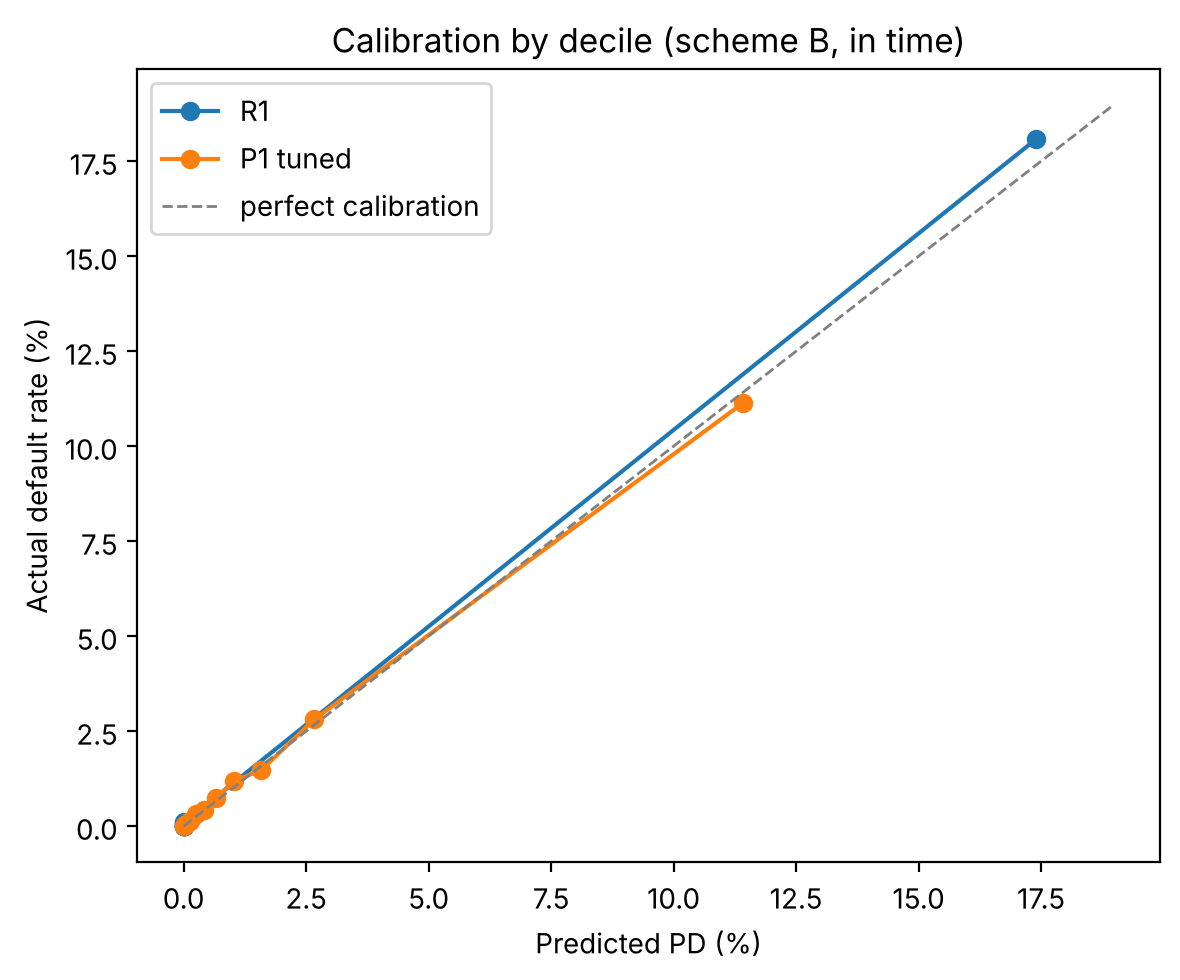

In [11]:
R1_FACTORY = lgbm_factory()                     # Section 3 kept the default
P1_FACTORY = lgbm_factory(**P1_TUNED)
oof_r1, oof_p1 = r1_conf['default']['oof'], p1_conf['tuned']['oof']

cal = pd.DataFrame({'R1': calibration_summary(y, oof_r1), 'P1 tuned': calibration_summary(y, oof_p1)}).T
display(cal.round(4))
print('P1 tuned by decile:'); display(calibration_table(y, oof_p1).round(4))

fig, ax = plt.subplots(figsize=(6, 5))
for name, p in [('R1', oof_r1), ('P1 tuned', oof_p1)]:
    t = calibration_table(y, p)
    ax.plot(t.predicted_pd * 100, t.actual_rate * 100, marker='o', label=name)
lim = max(ax.get_xlim()[1], ax.get_ylim()[1])
ax.plot([0, lim], [0, lim], ls='--', c='grey', lw=1, label='perfect calibration')
ax.set(xlabel='Predicted PD (%)', ylabel='Actual default rate (%)', title='Calibration by decile (scheme B, in time)')
ax.legend(); plt.tight_layout(); plt.show()

## 7. Calibration forward in time, and recalibration on recent outcomes

In [12]:
past, fut = ev.past, ~ev.past
d = train['disbursement_date']
y23 = (fut & (d < '2024-01-01')).to_numpy()
y24 = (fut & (d >= '2024-01-01')).to_numpy()
print(f"Forward period: {fut.sum():,} loans; 2023: {y23.sum():,} ({y[y23].mean():.1%} default), "
      f"2024: {y24.sum():,} ({y[y24].mean():.1%} default)")

rows = []
for name, cols, factory in [('R1', R1, R1_FACTORY), ('P1 tuned', P1, P1_FACTORY),
                            ('P1 logistic', P1, logistic_factory(['lender_id', 'loan_type']))]:
    ev.model_factory = factory
    p = np.full(len(y), np.nan)
    p[fut] = ev._fit_predict(ev.X[cols], y, past, fut)          # trained on pre-2023 loans only
    recal = platt_recalibrator(p[y23], y[y23])                  # recalibrate on 2023 outcomes...
    p24 = recal(p[y24])                                         # ...and test on 2024
    s_fut, s24_raw, s24_cal = (calibration_summary(y[fut], p[fut]), calibration_summary(y[y24], p[y24]),
                               calibration_summary(y[y24], p24))
    rows.append({'model': name, 'forward_auc': s_fut['roc_auc'], 'forward_mean_pred': s_fut['mean_predicted'],
                 'forward_actual': s_fut['actual_rate'], 'forward_ece': s_fut['expected_calibration_error'],
                 '2024_mean_raw': s24_raw['mean_predicted'], '2024_mean_recal': s24_cal['mean_predicted'],
                 '2024_actual': s24_raw['actual_rate'], '2024_ece_raw': s24_raw['expected_calibration_error'],
                 '2024_ece_recal': s24_cal['expected_calibration_error']})
forward = pd.DataFrame(rows).set_index('model')
display(forward.round(4))

Forward period: 4,210 loans; 2023: 1,240 (11.5% default), 2024: 2,970 (8.7% default)


,forward_auc,forward_mean_pred,forward_actual,forward_ece,2024_mean_raw,2024_mean_recal,2024_actual,2024_ece_raw,2024_ece_recal
model,,,,,,,,,
R1,0.9063,0.0610,0.0952,0.0343,0.0302,0.0273,0.0869,0.0567,0.0596
P1 tuned,0.5963,0.0709,0.0952,0.0620,0.0377,0.0844,0.0869,0.0501,0.0204
P1 logistic,0.6299,0.1166,0.0952,0.0578,0.0999,0.0976,0.0869,0.0495,0.0274


In [13]:
# Forward ranking and calibration per model, and the monitoring routine they imply.
forward['in_time_auc'] = pd.Series({'R1': cal.loc['R1', 'roc_auc'], 'P1 tuned': cal.loc['P1 tuned', 'roc_auc'],
                                    'P1 logistic': p1_table.loc['logistic', 'roc_auc_B']})
forward['auc_change'] = forward['forward_auc'] - forward['in_time_auc']
display(forward[['in_time_auc', 'forward_auc', 'auc_change', 'forward_mean_pred', 'forward_actual',
                 '2024_mean_raw', '2024_mean_recal', '2024_actual', '2024_ece_raw', '2024_ece_recal']].round(4))

ranking = '; '.join(f"{m} {forward.loc[m, 'in_time_auc']:.3f} -> {forward.loc[m, 'forward_auc']:.3f}"
                    for m in forward.index)
best_fwd = forward['forward_auc'].idxmax()
print(f"(a) Ranking (ROC AUC in time -> forward, trained before 2023 and scored on {fut.sum():,} loans from 2023-24): "
      f"{ranking}; {best_fwd} ranks future loans best, while P1 tuned loses "
      f"{-forward.loc['P1 tuned', 'auc_change']:.3f} of AUC.")

fixed = [m for m in forward.index if forward.loc[m, '2024_ece_recal'] < forward.loc[m, '2024_ece_raw']]
not_fixed = [m for m in forward.index if m not in fixed]
detail = '; '.join(
    f"{m} mean PD {forward.loc[m, '2024_mean_raw']:.1%} -> {forward.loc[m, '2024_mean_recal']:.1%} "
    f"vs {forward.loc[m, '2024_actual']:.1%} actual, gap {forward.loc[m, '2024_ece_raw'] * 100:.1f} -> "
    f"{forward.loc[m, '2024_ece_recal'] * 100:.1f} points" for m in forward.index)
print(f"(b) Recalibrating on {y23.sum():,} loans from 2023 and testing on {y24.sum():,} from 2024: {detail}; "
      f"the group gap shrinks for {', '.join(fixed) or 'no model'} and does not for {', '.join(not_fixed) or 'none'}.")

print(f"(c) Because level and ranking both drift (future loans defaulted at {forward.loc['R1', 'forward_actual']:.1%} "
      f"vs {y[past].mean():.1%} before 2023), I recommend a monthly routine: compare each matured vintage's actual "
      f"default rate with its mean predicted PD per risk band, recompute ROC AUC on matured loans, and track input "
      f"drift (PSI) on every feature; refit the Platt recalibrator on the latest 6-12 months whenever the calibration "
      f"gap exceeds 1 point, and send the model for retraining and review whenever matured-loan AUC drops more than "
      f"0.05 below its validation value or any PSI exceeds 0.25.")

,in_time_auc,forward_auc,auc_change,forward_mean_pred,forward_actual,2024_mean_raw,2024_mean_recal,2024_actual,2024_ece_raw,2024_ece_recal
model,,,,,,,,,,
R1,0.9933,0.9063,-0.0870,0.0610,0.0952,0.0302,0.0273,0.0869,0.0567,0.0596
P1 tuned,0.8716,0.5963,-0.2753,0.0709,0.0952,0.0377,0.0844,0.0869,0.0501,0.0204
P1 logistic,0.8393,0.6299,-0.2094,0.1166,0.0952,0.0999,0.0976,0.0869,0.0495,0.0274


(a) Ranking (ROC AUC in time -> forward, trained before 2023 and scored on 4,210 loans from 2023-24): R1 0.993 -> 0.906; P1 tuned 0.872 -> 0.596; P1 logistic 0.839 -> 0.630; R1 ranks future loans best, while P1 tuned loses 0.275 of AUC.
(b) Recalibrating on 1,240 loans from 2023 and testing on 2,970 from 2024: R1 mean PD 3.0% -> 2.7% vs 8.7% actual, gap 5.7 -> 6.0 points; P1 tuned mean PD 3.8% -> 8.4% vs 8.7% actual, gap 5.0 -> 2.0 points; P1 logistic mean PD 10.0% -> 9.8% vs 8.7% actual, gap 4.9 -> 2.7 points; the group gap shrinks for P1 tuned, P1 logistic and does not for R1.
(c) Because level and ranking both drift (future loans defaulted at 9.5% vs 1.3% before 2023), I recommend a monthly routine: compare each matured vintage's actual default rate with its mean predicted PD per risk band, recompute ROC AUC on matured loans, and track input drift (PSI) on every feature; refit the Platt recalibrator on the latest 6-12 months whenever the calibration gap exceeds 1 point, and send the

## 7b. Extra forward checks
Three questions the forward table leaves open: does tuning P1 hurt its forward ranking, where does R1 put 2024's
defaults, and did the loans themselves change after 2022?

In [14]:
# 7b. Extra forward-in-time checks (one fit each, trained on pre-2023 loans only)
from sklearn.metrics import roc_auc_score
fwd = {}
for name, cols, factory in [('R1', R1, R1_FACTORY), ('P1 tuned', P1, P1_FACTORY), ('P1 default', P1, lgbm_factory())]:
    ev.model_factory = factory
    p_full = np.full(len(y), np.nan)
    p_full[fut] = ev._fit_predict(ev.X[cols], y, past, fut)
    fwd[name] = p_full
for name in ['R1', 'P1 tuned']:      # same fits as Section 7, so these must match the forward table
    assert abs(roc_auc_score(y[fut], fwd[name][fut]) - forward.loc[name, 'forward_auc']) < 1e-9

fwd_rank = pd.DataFrame({m: {'in_time_auc': a, 'forward_auc': roc_auc_score(y[fut], fwd[m][fut])}
                         for m, a in [('P1 default', p1_table.loc['default', 'roc_auc_B']),
                                      ('P1 tuned', p1_table.loc['tuned', 'roc_auc_B'])]}).T
display(fwd_rank.round(4))

# Where do 2024 defaults sit? Share of 2024 loans scored below 1% PD, their default rate, and their share of defaults
low = pd.DataFrame({m: {'share_2024_loans_pd_below_1pct': (fwd[m][y24] < 0.01).mean(),
                        'default_rate_in_that_group': y[y24 & (fwd[m] < 0.01)].mean(),
                        'share_of_2024_defaults_in_it': y[y24 & (fwd[m] < 0.01)].sum() / y[y24].sum()}
                    for m in ['R1', 'P1 tuned']}).T
display(low.round(4))

# Did the loans change? The safe 7-day Type_1 product before vs from 2023
core = (train['loan_type'].eq('Type_1') & train['duration'].eq(7)).to_numpy()
mix = pd.DataFrame({period: {'loans': int(mask.sum()), 'default_rate': y[mask].mean(),
                             'share_type1_7day': core[mask].mean(),
                             'default_rate_type1_7day': y[mask & core].mean(),
                             'default_rate_other': y[mask & ~core].mean()}
                    for period, mask in [('before 2023', past), ('2023 onwards', fut)]}).T
display(mix.round(4))
print(f"P1 default ranks future loans at AUC {fwd_rank.loc['P1 default', 'forward_auc']:.3f} vs "
      f"{fwd_rank.loc['P1 tuned', 'forward_auc']:.3f} for P1 tuned.")

# Is P1's weak forward ranking drift, or weak ranking inside the riskier products even in time? (out-of-fold, scheme B)
seg = pd.DataFrame({lab: {'loans': int(m.sum()), 'default_rate': y[m].mean(), 'p1_oof_auc': roc_auc_score(y[m], oof_p1[m])}
                    for lab, m in [('all loans', np.ones(len(y), bool)), ('Type_1, 7-day', core),
                                   ('other products', ~core), ('other products, before 2023', ~core & past),
                                   ('other products, 2023 onwards', ~core & fut)]}).T
display(seg.round(4))
products = (pd.DataFrame({'loans_before_2023': train.loc[past, 'loan_type'].value_counts(),
                          'loans_2023_onwards': train.loc[fut, 'loan_type'].value_counts()})
              .fillna(0).astype(int).sort_values('loans_2023_onwards', ascending=False).head(6))
display(products)
core_dates = train.loc[core, 'disbursement_date']

# What did Platt scaling (fitted on 2023) do to each model? slope > 1 sharpens the scores, < 1 flattens them
from sklearn.linear_model import LogisticRegression
logit = lambda p: np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6)))
platt_fit = pd.DataFrame({m: dict(zip(['slope', 'intercept'],
                          [lr.coef_[0, 0], lr.intercept_[0]]))
                          for m in ['R1', 'P1 tuned']
                          for lr in [LogisticRegression().fit(logit(fwd[m][y23]).reshape(-1, 1), y[y23])]}).T
display(platt_fit.round(3))
print(f"Type_1 7-day loans were made only from {core_dates.min():%d %b %Y} to {core_dates.max():%d %b %Y}; "
      f"P1 tuned ranks the other products at AUC {seg.loc['other products', 'p1_oof_auc']:.3f} even in time, and "
      f"2023-24 loans at {seg.loc['other products, 2023 onwards', 'p1_oof_auc']:.3f} in time vs "
      f"{forward.loc['P1 tuned', 'forward_auc']:.3f} forward.")

,in_time_auc,forward_auc
P1 default,0.8572,0.5667
P1 tuned,0.8716,0.5963


,share_2024_loans_pd_below_1pct,default_rate_in_that_group,share_of_2024_defaults_in_it
R1,0.9185,0.0315,0.3333
P1 tuned,0.0549,0.0675,0.0426


,loans,default_rate,share_type1_7day,default_rate_type1_7day,default_rate_other
before 2023,64444.0,0.0133,0.9578,0.0084,0.1239
2023 onwards,4210.0,0.0952,0.0000,NaN,0.0952


P1 default ranks future loans at AUC 0.567 vs 0.596 for P1 tuned.


,loans,default_rate,p1_oof_auc
all loans,68654.0,0.0183,0.8716
"Type_1, 7-day",61723.0,0.0084,0.7985
other products,6931.0,0.1065,0.7284
"other products, before 2023",2721.0,0.1239,0.7690
"other products, 2023 onwards",4210.0,0.0952,0.6917


,loans_before_2023,loans_2023_onwards
loan_type,,
Type_7,0,2790
Type_4,492,743
Type_10,240,226
Type_9,0,205
Type_5,1386,135
Type_2,45,29


,slope,intercept
R1,0.474,-0.761
P1 tuned,0.249,-1.525


Type_1 7-day loans were made only from 12 Jul 2022 to 01 Dec 2022; P1 tuned ranks the other products at AUC 0.728 even in time, and 2023-24 loans at 0.692 in time vs 0.596 forward.


## 8. Competition threshold and the first tuned submission

In [15]:
r1_final = r1_conf['default']['r']
thr = r1_final['threshold_B']
thr_grid = np.round(np.arange(0.05, 0.95, 0.01), 2)
from sklearn.metrics import f1_score
curve = np.array([f1_score(y, oof_r1 >= t) for t in thr_grid])
near = thr_grid[curve >= curve.max() - 0.01]
print(f"R1 threshold from out-of-fold predictions: {thr:.2f} (F1 {curve.max():.3f}); "
      f"every threshold from {near.min():.2f} to {near.max():.2f} is within 0.01 of the best.")

test_prob = r1_conf['default']['test']
sub = pd.DataFrame({'ID': test['ID'], 'target': (test_prob >= thr).astype(int)})
sample = pd.read_csv(DATA / 'SampleSubmission.csv')
assert len(sub) == len(sample) and set(sub.ID) == set(sample.ID), 'IDs do not match SampleSubmission.csv'
sub.to_csv(OUT / 'sub_m4_r1.csv', index=False)
by_country = sub.assign(country=test['country_id'].values).groupby('country')['target'].agg(['size', 'sum', 'mean'])
display(by_country)
prev = pd.read_csv(OUT / 'sub_m2_baseline.csv').set_index('ID').loc[sub.ID, 'target'].to_numpy()
print(f"Saved outputs/sub_m4_r1.csv: {sub.target.sum():,} predicted defaults of {len(sub):,}; "
      f"agrees with the notebook 02 baseline on {(prev == sub.target.to_numpy()).mean():.1%} of rows.")

R1 threshold from out-of-fold predictions: 0.30 (F1 0.836); every threshold from 0.18 to 0.53 is within 0.01 of the best.


,size,sum,mean
country,,,
Ghana,3525,369,0.104681
Kenya,15069,297,0.019709


Saved outputs/sub_m4_r1.csv: 666 predicted defaults of 18,594; agrees with the notebook 02 baseline on 99.2% of rows.


In [16]:
# Leaderboard diagnostics: the same Kenya predictions with every Ghana loan set to 0, then to 1. Their public and
# private scores (outputs/leaderboard_scores.csv) let notebook 05 estimate the Ghana default rate. Diagnostic only:
# they never feed back into the model or the submission.
for name, value in [('ghana0', 0), ('ghana1', 1)]:
    probe = sub.assign(target=np.where(test['country_id'].eq('Ghana').values, value, sub.target))
    probe.to_csv(OUT / f'probe_r1_{name}.csv', index=False)
print('Saved outputs/probe_r1_ghana0.csv and outputs/probe_r1_ghana1.csv')

Saved outputs/probe_r1_ghana0.csv and outputs/probe_r1_ghana1.csv


## 9. Production scores for notebook 05
Notebook 05 turns these scores into risk bands. We save the out-of-fold scores (to build and test the bands on known
outcomes) and the test scores (to apply them).

In [17]:
p1_test = p1_conf['tuned']['test']
pd.DataFrame({'ID': train['ID'], 'pd_p1': oof_p1, 'target': y}).to_csv(OUT / 'scores_p1_oof.csv', index=False)
pd.DataFrame({'ID': test['ID'], 'country_id': test['country_id'], 'pd_p1': p1_test}).to_csv(OUT / 'scores_p1_test.csv', index=False)
print(f"Saved P1 scores. Top 10% of out-of-fold scores holds {top_share(y, oof_p1):.0%} of defaults. "
      f"Mean test PD: Kenya {p1_test[test.country_id.eq('Kenya').values].mean():.2%}, "
      f"Ghana {p1_test[test.country_id.eq('Ghana').values].mean():.2%}.")

(OUT / 'model_settings.json').write_text(json.dumps({
    'competition': {'features': R1, 'model': 'LightGBM', 'params': {}, 'threshold': float(thr)},
    'production': {'features': P1, 'model': 'LightGBM', 'params': P1_TUNED},
}, indent=2))
print('Saved outputs/model_settings.json')

Saved P1 scores. Top 10% of out-of-fold scores holds 61% of defaults. Mean test PD: Kenya 1.73%, Ghana 12.39%.
Saved outputs/model_settings.json


## 10. Assumptions log (modelling)
Rows 1-7 are in notebook 03.

| # | Assumption | Evidence | Status |
| --- | --- | --- | --- |
| 8 | Default LightGBM settings are adequate for R1 | Section 3: no tuned setting passed the guardrails; the best on scheme B lost 0.157 F1 on scheme D; two extra settings gained under 0.002 (3/5 folds) | Holds |
| 9 | Production models are judged on ranking (ROC AUC, held-out-lender AUC) | Track ends in risk bands; F1 on held-out lenders is unstable | Adopted |
| 10 | In-time calibration carries forward | Section 7: forward ranking and level both degrade | **Fails**: recalibrate on recent outcomes and monitor |
| 11 | The test set resembles the training period for Kenya | Notebook 02 adversarial AUC 0.50 | Holds for Kenya; not for Ghana |
| 12 | P1 is the production model although it failed the v2 F1 rule | Notebook 03b: B +0.006, 3/5 folds vs P0; ROC AUC 0.857 vs 0.798; P1 tuned beats P1 default in 5/5 folds | **Adopted on ranking**; decision recorded here |
| 13 | Logistic regression flags Ghana because Ghana values fall outside the Kenyan range | Section 5: unseen codes become all-zero one-hot; giving Ghana the average Kenyan category effect cuts flags from 56.9% to 2.3%; largest numeric push only +0.46 log-odds | **Fails**: cause is the encoding of unseen codes; logistic deserves a rematch with an explicit unknown level |
| 14 | Recalibrating on recent outcomes restores the level of both models | 2024 group gap: P1 tuned 5.0 → 2.0 points; R1 5.7 → 6.0 | Holds for P1 only |
| 15 | Tuning P1 for in-time AUC does not hurt its forward ranking | Section 7b: forward AUC 0.596 tuned vs 0.567 default | Holds |
| 16 | Scheme D measures drift over time on the same kind of loans | Section 7b: Type_1 7-day loans (96% of pre-2023 loans) were made only 12 Jul-1 Dec 2022 and none from 2023; Type_7 (2,790 loans) is new from 2023; P1 ranks non-Type_1 products at AUC 0.728 even in time | **Fails**: D mostly measures transfer to new products; notebook 05 must check bands within products |